# Solving Inverse Problem using Connectome Spectrum Electromagnetic Tomography (CSET)

In this section we will solve the inverse problem using our new method CSET. This requires the eeg measurements, the forward solution and the connectome spectrum transform (prior). <br>
The method solves the following problem: $$\vec{x}^* = \text{argmin}_{\vec{x}} \lVert A\vec{x}-b \rVert_2^2 + \lambda \lVert F\vec{x}\rVert_1$$
where
- $\vec{x}^* \in \mathbb{R}^n$ is the reconstructed brain activity.
- $\vec{x} \in \mathbb{R}^n$ is the brain activity.
- $\vec{b} \in \mathbb{R}^m$ are the eeg measurements.
- $A \in \mathbb{R}^{m\times n}$ is the forward matrix.
- $F \in \mathbb{R}^{n \times n}$ is the connectome spectrum transform.
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert F\vec{x} \rVert_1$ imposes the connectome spectrum of $\vec{x}$ to be sparse and $\lambda$ 

## 📦 Imports

In [30]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

In [31]:
# configuration
sub    = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")
sample = "sample6"

# data
data = mm.io.read_dataset(sub, "fwd", "cst", "eeg_inv", "gt", sample=sample)

# features
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                              # forward matrix

sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03}")
print(f"Peak time: {t_peak:03}")

50% rising phase time: 0.504
Peak time: 0.548


#### 🌟 Visualize ground truth

In [32]:
try:
    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)
except KeyError as e:
    print("No ground truth available.")

Widget(value='<iframe src="http://localhost:34261/index.html?ui=P_0x7954f43d48c0_13&reconnect=auto" class="pyv…

In [51]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(data["gt"].data[:,ht]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:34261/index.html?ui=P_0x795513dd3ce0_39&reconnect=auto" class="pyv…

In [33]:
mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht])

#### 🌟 Visualize EEG time series

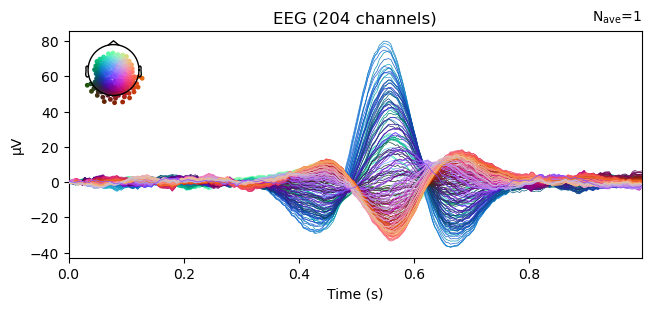

In [34]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

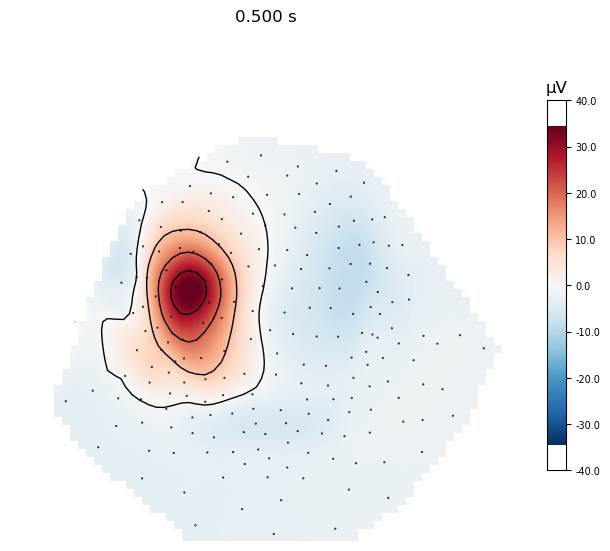

In [35]:
times = [0.5]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

#### 🌟 Visualize forward matrix

In [36]:
mm.viz.plot_leadfield(data["eeg_inv"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:34261/index.html?ui=P_0x795516645610_15&reconnect=auto" class="pyv…

#### 🌟 Visualize connectome spectrum transform

In [37]:
signal = data["cst"][1]
max_abs = max(abs(signal.max()), abs(signal.min()))
clim    = [-max_abs, max_abs]
mm.viz.plot_brain_signal(data["fwd"]["src"], signal, clim=clim).show()

Widget(value='<iframe src="http://localhost:34261/index.html?ui=P_0x795500d13a10_16&reconnect=auto" class="pyv…

## Solve The Inverse Problem with CSET

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct.
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 2


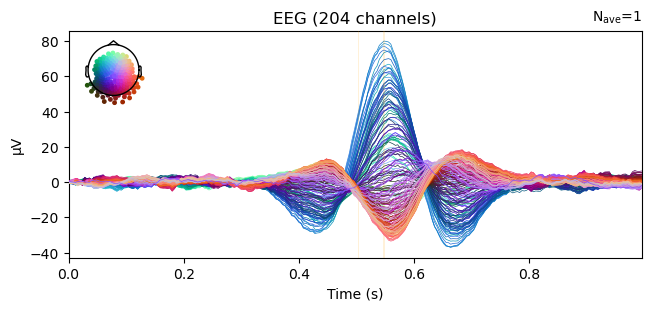

In [38]:
win_size = None      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    b  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    b = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {b.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

🛠️ <font color=violet>**Select CSET parameters**</font> 
- $\lambda$ (`lam`): regularizer parameter (influences the connectome spectrum sparsity)

In [55]:
l_sparse = 1          # cst sparsness regularizer
l_smooth = None            # cst smoothness regularizer
l_dw     = 0.2          # depth weighting regularizer

cut_freq = None         # cst cut off frequency

⚙️ <font color=green>**Solve inverse problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [56]:
# ----- Optimization problem -----

# frequency cutoff
if cut_freq is not None:
    cst = data["cst"][:cut_freq,:]
else:
    cst = data["cst"]

# prior cst sparsity
if l_sparse is not None:
    priorCST1 = l_sparse*pxo.L1Norm(dim_shape=cst.shape[0]) 
else: 
    priorCST1 = None

# prior cst smoothness
if l_smooth is not None:
    priorCST2 = l_smooth*pxo.SquaredL2Norm(dim_shape=cst.shape[0]) 
else:
    priorCST2 = None

# depth weighting
if l_dw is not None:
    W = np.linalg.norm(fwd, axis=0)
    W = np.diag(W) @ cst.T
    W = pxa.LinOp.from_array(W)

    priorW = l_dw * pxo.SquaredL2Norm(dim_shape=cst.shape[1])*W

else:
    priorW = None

# forward operator
A = fwd @ cst.T
A = pxa.LinOp.from_array(A)


# ----- Data preprocessing -----
bnorms = np.linalg.norm(b, axis=0)
bn     = b/bnorms[None,:]

# ----- Optimization options -----

# initial guess
alpha0 = np.random.random(A.dim_shape)*10**(-9)

# stopping criterion (number of iteration only)
sc = pxst.MaxIter(1000)

# ----- Optimization solving -----
recon = np.zeros((cst.shape[1], b.shape[1]))
for t in range(b.shape[1]):
    bt    = bn[:,t]     # data time point

    likelihood = pxo.SquaredL2Norm(dim_shape=A.codim_shape).argshift(-bt)*A

    if priorCST2 is not None:
        likelihood = likelihood + priorCST2 
    if priorW is not None:
        likelihood = likelihood + priorW

    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=priorCST1, show_progress=False)

    solver.fit(x0=alpha0, stop_crit=sc)

    alpha = solver.solution().squeeze()
    recon[:,t] = (cst.T @ alpha) * bnorms[t]

#### <font color=yellow>🌟</font> Visualize reconstruction

In [57]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(recon[:,idx_peak]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:34261/index.html?ui=P_0x795513d3d2e0_43&reconnect=auto" class="pyv…

In [27]:
mm.viz.plot_spectrum(data["cst"]@recon[:,idx_half])

#### 💾 Save result

In [12]:
fname  = f"{sub}_{sample}_cset-{lam}"
folder = Path(config["MM_DIR"])/sub/"stc"/config["DATA"]

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving source time course of {sub}, {sample}")
vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc = mne.SourceEstimate(recon, vertices, tmin=t_start, tstep=1/sfreq, subject=sub)
stc.save(folder/fname, overwrite=True, verbose="warning")

Saving source time course of sub-CHUVA002_ses-V1, sample1


## Apply CSET on dataset

🛠️ <font color=violet>**Select dataset parameters**</font>

In [13]:
subjects  = ["sub-CHUVA002_ses-V1"]
samples   = [f"sample{i+1}" for i in range(10)]
overwrite = False                               # If True, overwrite existing estimations

🛠️ <font color=violet>**Select reconstruction parameters**</font>

In [14]:
win_size = 0.2      # window size in [s]
lam      = 0.1      # regularizer parameter

⚙️ <font color=green>**Iterate through dataset and apply CSET**</font>

In [15]:
folder = Path(config["MM_DIR"])/sub/"stc"/config["DATA"]

if folder.exists() == False:
    folder.mkdir(parents=True)

for sub in subjects:
    data_sub = mm.io.read_dataset(sub, "fwd", "cst")

    for samp in samples:

        fname = folder/f"{sub}_{samp}_cset-{lam}-lh.stc"
        if (fname.exists() == True) and (overwrite == False):
            print(f"Skipping {sub}, {samp} because estimation already exists.")
            continue

        data_samp = mm.io.read_dataset(sub, "eeg_inv", sample=samp)
        recon     = mm.inv.recon_cset(data_samp["eeg_inv"], data_sub["fwd"], data_sub["cst"], win_size, lam)
        
        print(f"Saving source estimation of subject {sub}, {samp}")
        fname = folder/f"{sub}_{samp}_cset-{lam}"
        stc.save(fname, overwrite=True, verbose="warning")

Skipping sub-CHUVA002_ses-V1, sample1 because estimation already exists.
Saving source estimation of subject sub-CHUVA002_ses-V1, sample2
Saving source estimation of subject sub-CHUVA002_ses-V1, sample3
Saving source estimation of subject sub-CHUVA002_ses-V1, sample4
Saving source estimation of subject sub-CHUVA002_ses-V1, sample5
Saving source estimation of subject sub-CHUVA002_ses-V1, sample6
Saving source estimation of subject sub-CHUVA002_ses-V1, sample7
Saving source estimation of subject sub-CHUVA002_ses-V1, sample8
Saving source estimation of subject sub-CHUVA002_ses-V1, sample9
Saving source estimation of subject sub-CHUVA002_ses-V1, sample10


# Testing new CSET

In [117]:
test = recon_cset(data["eeg_inv"], data["fwd"], data["cst"], win_size=0.05)

In [118]:
viz     = np.abs(test.data / np.linalg.norm(test.data, axis=0)[None,:])         # so that each time point has a nice visualization
clim    = [0, np.max(viz)]
t_start = pt/sfreq-(win_size/2)
mm.viz.plot_brain_time_series(data["fwd"]["src"], np.abs(viz), t_start=t_start, sfreq=sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:37355/index.html?ui=P_0x7a6d38e80320_85&reconnect=auto" class="pyv…

In [119]:
mm.viz.plot_spectrum(data["cst"]@recon[:,int(recon.shape[1]/2)])